# Phase 2b: Residual spike removal
Phase 2 removed NaN / 9999 / text entries, but your own "cleaned" plots still show isolated spikes (chest_acc_x going to about -62 and +49 while the real signal sits near -8; ankle_gyro_x jumping to about +-4 while the real signal is about 0.1). They were hidden earlier because 9999 dominated the y-axis.

Evidence they are corruption, not motion:
- about 5% of train readings are such spikes, vs about 0.01% in the test set, and test is clean elsewhere
- train std is 2-3x the test std on every channel (std ratio 0.27-0.6) only because of the spikes; after despiking the ratio is about 1
- the spike sign is random and the size is roughly constant per channel

**Method** (per window and channel, no information from other rows, so no leakage): a reading is a spike if it deviates from the running median (width 7) by more than 5x that window's robust spread. Spikes are replaced by linear interpolation. Two passes handle spikes that sit next to each other.

Input `clean_data.npz`, output `clean_data_v2.npz`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import medfilt

d = np.load("clean_data.npz", allow_pickle=False)
X_tr, y, X_te = d["X_train"], d["y_train"], d["X_test"]
channels = list(d["channels"]); train_ids, test_ids = d["train_ids"], d["test_ids"]
T = np.arange(X_tr.shape[1])
print(X_tr.shape, X_te.shape)

(635, 250, 23) (403, 250, 23)


In [ ]:
K, W, PASSES = 5, 7, 2

def despike(A, k=K, w=W, passes=PASSES):

    A = A.copy(); flag = np.zeros(A.shape, bool)
    for _ in range(passes):
        med = np.apply_along_axis(lambda v: medfilt(v, w), 1, A)
        r = A - med
        # robust spread of the window itself (not affected by a few spikes)
        s = 1.4826 * np.median(np.abs(A - np.median(A, 1, keepdims=True)), 1, keepdims=True)
        new = (np.abs(r) > k * s) & ~flag
        if not new.any(): break
        flag |= new
        for i in np.where(new.any(1))[0]:
            good = ~flag[i]
            A[i, flag[i]] = np.interp(T[flag[i]], T[good], A[i, good])
    return A, flag

def despike_all(X):
    out, mask = np.empty_like(X), np.empty(X.shape, bool)
    for c in range(X.shape[2]):
        out[:, :, c], mask[:, :, c] = despike(X[:, :, c])
    return out, mask

Xtr_c, m_tr = despike_all(X_tr)
Xte_c, m_te = despike_all(X_te)
print("flagged share  train: %.3f   test: %.4f" % (m_tr.mean(), m_te.mean()))

flagged share  train: 0.058   test: 0.0036


## Sanity checks
Test should have almost nothing flagged (test is clean); train around 5-6%. If test flags a lot, lower `K` is too aggressive.

In [3]:
print(pd.DataFrame({"train_flag": m_tr.mean((0, 1)), "test_flag": m_te.mean((0, 1))}, index=channels).round(4))

tr, te = X_tr.reshape(-1, 23), X_te.reshape(-1, 23)
tr_c, te_c = Xtr_c.reshape(-1, 23), Xte_c.reshape(-1, 23)
print(pd.DataFrame({"std_ratio_before": te.std(0) / tr.std(0), "std_ratio_after": te_c.std(0) / tr_c.std(0)},
                   index=channels).round(2))

              train_flag  test_flag
chest_acc_x       0.0493     0.0001
chest_acc_y       0.0551     0.0009
chest_acc_z       0.0584     0.0005
chest_ecg_1       0.0930     0.0297
chest_ecg_2       0.0860     0.0173
ankle_acc_x       0.0599     0.0069
ankle_acc_y       0.0582     0.0114
ankle_acc_z       0.0558     0.0036
ankle_gyro_x      0.0590     0.0001
ankle_gyro_y      0.0566     0.0000
ankle_gyro_z      0.0575     0.0001
ankle_mag_x       0.0502     0.0039
ankle_mag_y       0.0568     0.0049
ankle_mag_z       0.0546     0.0008
arm_acc_x         0.0502     0.0008
arm_acc_y         0.0517     0.0002
arm_acc_z         0.0552     0.0003
arm_gyro_x        0.0582     0.0000
arm_gyro_y        0.0578     0.0000
arm_gyro_z        0.0589     0.0000
arm_mag_x         0.0469     0.0001
arm_mag_y         0.0524     0.0008
arm_mag_z         0.0505     0.0001
              std_ratio_before  std_ratio_after
chest_acc_x               0.43             0.78
chest_acc_y               0.27          

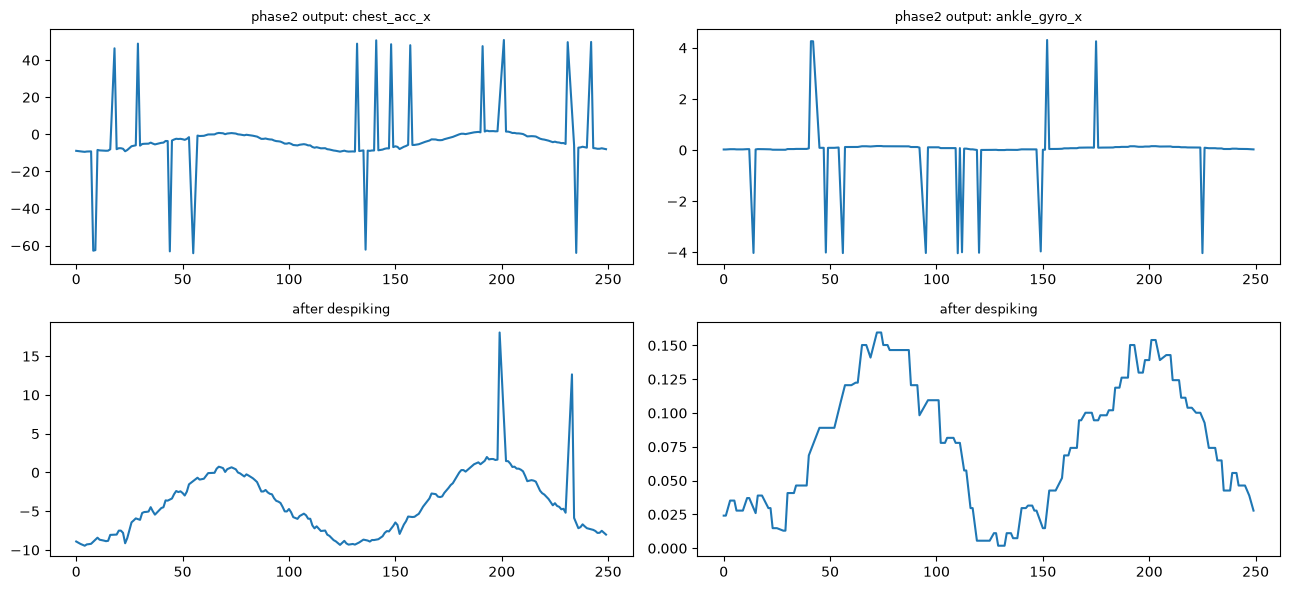

In [4]:
i = 372   # same window as your Phase 2 plot
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for col, ch in enumerate([0, 8]):
    ax[0, col].plot(X_tr[i, :, ch]); ax[0, col].set_title(f"phase2 output: {channels[ch]}", fontsize=9)
    ax[1, col].plot(Xtr_c[i, :, ch]); ax[1, col].set_title("after despiking", fontsize=9)
plt.tight_layout(); plt.show()

In [5]:
np.savez_compressed("clean_data_v2.npz", X_train=Xtr_c, y_train=y, train_ids=train_ids,
                    X_test=Xte_c, test_ids=test_ids, channels=np.array(channels))
print("saved clean_data_v2.npz")

saved clean_data_v2.npz
